In [11]:
from pathlib import Path
import pandas as pd

data_path = Path(r"D:\Downloads\e-commercedata\last")

files = list(data_path.glob("*.csv"))

for file in files:
    print(file.name)

customers.csv
geo_data.csv
marketing_campaigns.csv
sample_submission.csv
sessions.csv
test.csv
train.csv
transactions.csv


In [12]:
customers = pd.read_csv(data_path / "customers.csv")
geo_data = pd.read_csv(data_path / "geo_data.csv")
marketing = pd.read_csv(data_path / "marketing_campaigns.csv")
sessions = pd.read_csv(data_path / "sessions.csv")
transactions = pd.read_csv(data_path / "transactions.csv")
train = pd.read_csv(data_path / "train.csv")
test = pd.read_csv(data_path / "test.csv")

In [13]:
datasets = {
    "customers": customers,
    "geo_data": geo_data,
    "marketing": marketing,
    "sessions": sessions,
    "transactions": transactions,
    "train": train,
    "test": test
}

for name, df in datasets.items():
    print(f"{name}: {df.shape}")

customers: (200000, 17)
geo_data: (100, 5)
marketing: (200, 6)
sessions: (2000000, 11)
transactions: (500000, 11)
train: (160000, 2)
test: (40000, 1)


In [14]:
for name, df in datasets.items():

    print(f"DATASET: {name}")
   

    print("Columns:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

DATASET: customers
Columns:
['customer_id', 'age', 'country_code', 'region', 'signup_date', 'loyalty_score', 'email_open_rate', 'discount_usage_rate', 'avg_review_score', 'referral_code', 'customer_tier', 'credit_limit', 'noise_customer_0', 'noise_customer_1', 'noise_customer_2', 'noise_customer_3', 'noise_customer_4']

Data Types:
customer_id              int64
age                     object
country_code            object
region                  object
signup_date             object
loyalty_score          float64
email_open_rate        float64
discount_usage_rate    float64
avg_review_score       float64
referral_code           object
customer_tier           object
credit_limit            object
noise_customer_0       float64
noise_customer_1       float64
noise_customer_2       float64
noise_customer_3       float64
noise_customer_4       float64
dtype: object
DATASET: geo_data
Columns:
['geo_ip_region', 'average_income', 'urban_ratio', 'internet_penetration', 'region_tier']

Data Ty

In [15]:
for name, df in datasets.items():
    print("Missing values:")
    print(df.isnull().sum())

Missing values:
customer_id                0
age                        0
country_code               0
region                     0
signup_date                0
loyalty_score              0
email_open_rate        22746
discount_usage_rate        0
avg_review_score           0
referral_code              0
customer_tier              0
credit_limit               0
noise_customer_0           0
noise_customer_1           0
noise_customer_2           0
noise_customer_3           0
noise_customer_4           0
dtype: int64
Missing values:
geo_ip_region           0
average_income          0
urban_ratio             0
internet_penetration    0
region_tier             0
dtype: int64
Missing values:
campaign_id        0
campaign_type      0
campaign_budget    0
region_target      0
start_date         0
end_date           0
dtype: int64
Missing values:
session_id                0
customer_id               0
session_timestamp         0
session_duration          0
pages_viewed         100000
cart_add

In [16]:
for name, df in datasets.items():
    print(f"{name}: {df.duplicated().sum()} duplicate rows")

customers: 0 duplicate rows
geo_data: 0 duplicate rows
marketing: 0 duplicate rows
sessions: 0 duplicate rows
transactions: 0 duplicate rows
train: 0 duplicate rows
test: 0 duplicate rows


In [17]:
categorical_cols = customers.select_dtypes(include="object").columns

for col in categorical_cols:
    print("Unique values:", customers[col].nunique())
    print(customers[col].value_counts().head(10))

Unique values: 58
age
unknown    10000
40          3517
62          3431
34          3424
32          3418
61          3402
30          3401
22          3399
65          3398
43          3396
Name: count, dtype: int64
Unique values: 10
country_code
usa     20185
USA     20144
UK      20131
uk      20063
US      20018
FR      19950
de      19948
U.S.    19859
IN      19858
DE      19844
Name: count, dtype: int64
Unique values: 100
region
region_18    2117
region_85    2113
region_35    2099
region_41    2084
region_96    2076
region_14    2075
region_36    2066
region_65    2061
region_79    2061
region_20    2059
Name: count, dtype: int64
Unique values: 1000
signup_date
2023-03-03    241
2023-12-28    241
2023-05-02    240
2023-01-01    237
2024-08-17    236
2024-04-04    235
2022-11-19    235
2024-05-18    234
2022-04-30    234
2022-06-13    233
Name: count, dtype: int64
Unique values: 179259
referral_code
REF_301278    5
REF_915713    5
REF_782472    5
REF_416376    5
REF_328716    5

In [18]:
# Check age values
print("AGE ANALYSIS")
print("Unknown values:", (customers["age"] == "unknown").sum())

age_numeric = pd.to_numeric(customers["age"], errors="coerce")

print("Minimum age:", age_numeric.min())
print("Maximum age:", age_numeric.max())
print("Invalid values:", age_numeric.isna().sum())

# Check all country codes
print("\nCOUNTRY CODE ANALYSIS")
print(sorted(customers["country_code"].unique()))

AGE ANALYSIS
Unknown values: 10000
Minimum age: 18.0
Maximum age: 74.0
Invalid values: 10000

COUNTRY CODE ANALYSIS
['DE', 'FR', 'IN', 'U.S.', 'UK', 'US', 'USA', 'de', 'uk', 'usa']


In [19]:
customers.describe()

,customer_id,loyalty_score,email_open_rate,discount_usage_rate,avg_review_score,noise_customer_0,noise_customer_1,noise_customer_2,noise_customer_3,noise_customer_4
count,200000.000000,200000.000000,177254.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000,200000.000000
mean,99999.500000,0.285373,0.333723,0.332457,3.999525,0.001636,0.003425,-0.001988,0.000120,0.001797
std,57735.171256,0.159726,0.178774,0.200737,0.499866,1.001075,1.000676,0.997289,0.998785,1.004185
min,0.000000,0.001000,0.000216,0.000265,1.569531,-4.508246,-4.617893,-4.475082,-4.500079,-4.394038
25%,49999.750000,0.161000,0.193740,0.170581,3.662075,-0.675191,-0.672970,-0.676830,-0.672260,-0.672174
50%,99999.500000,0.264000,0.314160,0.305570,3.999237,-0.002383,0.000538,-0.002668,-0.002154,0.002119
75%,149999.250000,0.389000,0.454961,0.469211,4.337399,0.675612,0.680519,0.670752,0.674994,0.679874
max,199999.000000,0.937000,0.951867,0.982597,6.389763,4.960137,5.618037,4.393881,5.179307,4.263112


In [20]:
print("Review scores above 5:")
print((customers["avg_review_score"] > 5).sum())

print("\nReview scores below 1:")
print((customers["avg_review_score"] < 1).sum())

print("\nReview score distribution:")
print(customers["avg_review_score"].describe())


Review scores above 5:
4489

Review scores below 1:
0

Review score distribution:
count    200000.000000
mean          3.999525
std           0.499866
min           1.569531
25%           3.662075
50%           3.999237
75%           4.337399
max           6.389763
Name: avg_review_score, dtype: float64


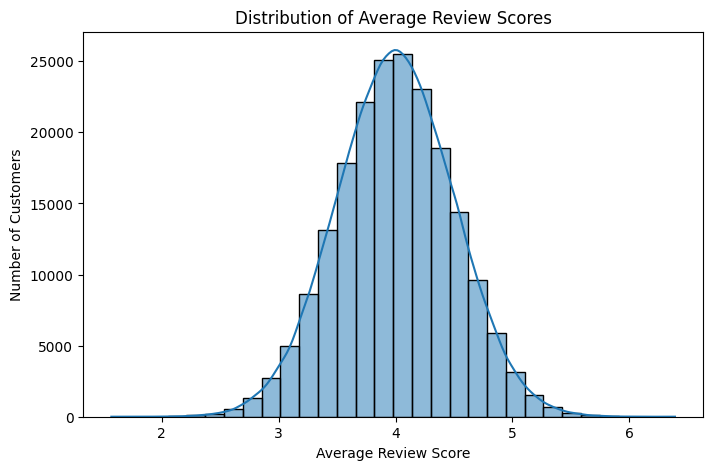

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))

sns.histplot(
    data=customers,
    x="avg_review_score",
    bins=30,
    kde=True
)

plt.title("Distribution of Average Review Scores")
plt.xlabel("Average Review Score")
plt.ylabel("Number of Customers")

plt.show()

### Findings – Average Review Score

- The distribution is approximately bell-shaped.
- Most customer review scores are concentrated around 4.
- The mean and median are approximately 4.
- 4,489 values (2.24%) exceed the expected maximum score of 5.
- These values require further investigation during data cleaning.

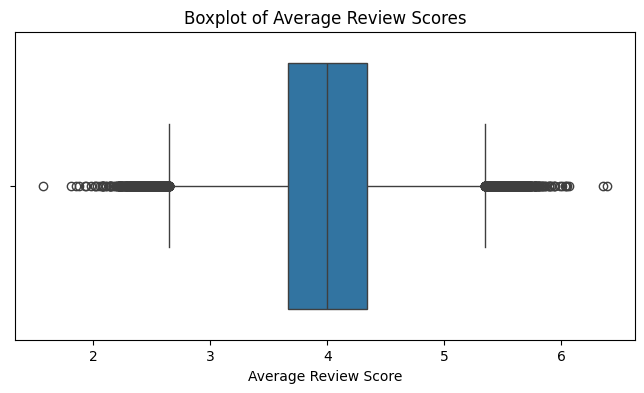

In [22]:
plt.figure(figsize=(8, 4))

sns.boxplot(x=customers["avg_review_score"])

plt.title("Boxplot of Average Review Scores")
plt.xlabel("Average Review Score")

plt.show()

### Findings – Average Review Score Boxplot

- The median review score is approximately 4.
- The middle 50% of scores are concentrated between 3.66 and 4.34.
- The boxplot identifies statistical outliers on both sides.
- Some values exceed the expected maximum score of 5.
- Statistical outliers should not automatically be treated as invalid values.

In [23]:
Q1 = customers["avg_review_score"].quantile(0.25)
Q3 = customers["avg_review_score"].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = customers[
    (customers["avg_review_score"] < lower_bound) |
    (customers["avg_review_score"] > upper_bound)
]

print("Lower Bound:", lower_bound)
print("Upper Bound:", upper_bound)
print("Total Statistical Outliers:", len(outliers))
print("Outliers below lower bound:",
      (customers["avg_review_score"] < lower_bound).sum())
print("Outliers above upper bound:",
      (customers["avg_review_score"] > upper_bound).sum())

Lower Bound: 2.6490881992700546
Upper Bound: 5.350386040677699
Total Statistical Outliers: 1353
Outliers below lower bound: 660
Outliers above upper bound: 693


In [24]:
# matplotlib draws charts, seaborn makes some charts easier (countplot, boxplot, heatmap)
import matplotlib.pyplot as plt
import seaborn as sns

# One clean style (white background with light grid lines) for every chart
sns.set_style("whitegrid")

# sample_submission.csv was not loaded in Part 1, so we load it now
sample_submission = pd.read_csv(data_path / "sample_submission.csv")
print("sample_submission shape:", sample_submission.shape)

sample_submission shape: (40000, 2)


In [25]:
print("Number of rows:", len(customers))
print("Is customer_id unique?", customers["customer_id"].is_unique)
print("Smallest ID:", customers["customer_id"].min())
print("Largest ID:", customers["customer_id"].max())

Number of rows: 200000
Is customer_id unique? True
Smallest ID: 0
Largest ID: 199999


In [26]:
# errors="coerce" means: if a value cannot become a number (like "unknown"), make it NaN instead of crashing
age_num = pd.to_numeric(customers["age"], errors="coerce")

# isna() marks the empty (NaN) values, sum() counts them
print("Unknown ages:", age_num.isna().sum())
print("Share of unknown ages:", age_num.isna().mean())
print(age_num.describe())

Unknown ages: 10000
Share of unknown ages: 0.05
count    190000.000000
mean         45.962011
std          16.424399
min          18.000000
25%          32.000000
50%          46.000000
75%          60.000000
max          74.000000
Name: age, dtype: float64


### Country code
The same country is written in different ways (`usa`, `USA`, `US`, `U.S.`). We make a view called `country_view` where the spelling is unified, so we can see the real sizes. The original column is not changed.

In [28]:
# Counts exactly as stored (10 spellings)
print(customers["country_code"].value_counts())

country_code
usa     20185
USA     20144
UK      20131
uk      20063
US      20018
FR      19950
de      19948
U.S.    19859
IN      19858
DE      19844
Name: count, dtype: int64


In [29]:
# upper() makes all letters capital: "usa" -> "USA"
country_view = customers["country_code"].str.upper()
# remove the dots: "U.S." -> "US"
country_view = country_view.str.replace(".", "", regex=False)
# make the last variant match: "USA" -> "US"
country_view = country_view.replace("USA", "US")

print(country_view.value_counts())

country_code
US    80206
UK    40194
DE    39792
FR    19950
IN    19858
Name: count, dtype: int64


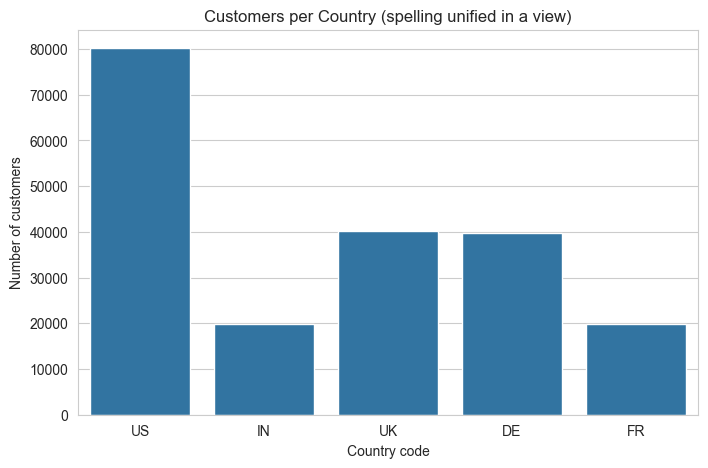

In [30]:
plt.figure(figsize=(8, 5))
sns.countplot(x=country_view)
plt.title("Customers per Country (spelling unified in a view)")
plt.xlabel("Country code")
plt.ylabel("Number of customers")
plt.show()


### Findings – Country
- Ten spellings hide only **five countries**: US, UK, DE, FR, IN.
- The US appears in four spellings, so it has about 80,000 customers (about 40%). UK and DE have two spellings each and about 40,000 customers each. FR and IN have one spelling each and about 20,000 customers each.
- **Question for the team:** is `US` the correct final spelling?

In [31]:
print(customers["customer_tier"].value_counts())
print(customers["customer_tier"].value_counts(normalize=True))

customer_tier
Platinum    50281
Gold        50139
Bronze      50130
Silver      49450
Name: count, dtype: int64
customer_tier
Platinum    0.251405
Gold        0.250695
Bronze      0.250650
Silver      0.247250
Name: proportion, dtype: float64


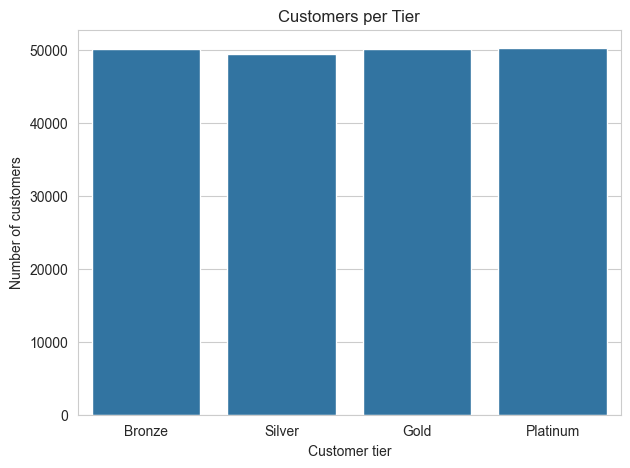

In [32]:
plt.figure(figsize=(7, 5))
# order=[...] sets the order of the bars from lowest to highest tier
sns.countplot(x=customers["customer_tier"], order=["Bronze", "Silver", "Gold", "Platinum"])
plt.title("Customers per Tier")
plt.xlabel("Customer tier")
plt.ylabel("Number of customers")
plt.show()

### Findings – Tier
- The four tiers are almost equal (about 25% each; Silver is a little lower at 24.7%).
- In a real shop Bronze is usually much bigger than Platinum. Equal sizes suggest the data may be **simulated**, or that tier is not based on spending. **Question for the team:** how is tier calculated?

### Loyalty score, email open rate, discount usage rate
These three scores should be between 0 and 1. First we check the range, then we draw one chart for each.

In [33]:
# Count values below 0 and above 1 (we expect 0 for both)
print("loyalty_score below 0:", (customers["loyalty_score"] < 0).sum())
print("loyalty_score above 1:", (customers["loyalty_score"] > 1).sum())
print("email_open_rate below 0:", (customers["email_open_rate"] < 0).sum())
print("email_open_rate above 1:", (customers["email_open_rate"] > 1).sum())
print("discount_usage_rate below 0:", (customers["discount_usage_rate"] < 0).sum())
print("discount_usage_rate above 1:", (customers["discount_usage_rate"] > 1).sum())

loyalty_score below 0: 0
loyalty_score above 1: 0
email_open_rate below 0: 0
email_open_rate above 1: 0
discount_usage_rate below 0: 0
discount_usage_rate above 1: 0


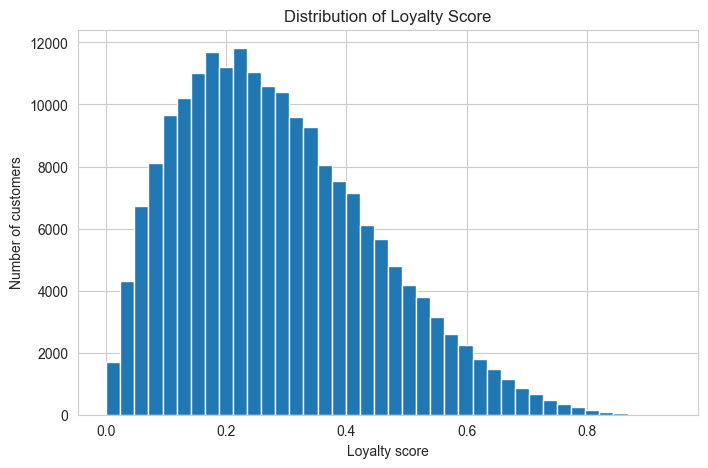

In [34]:
plt.figure(figsize=(8, 5))
plt.hist(customers["loyalty_score"], bins=40)
plt.title("Distribution of Loyalty Score")
plt.xlabel("Loyalty score")
plt.ylabel("Number of customers")
plt.show()

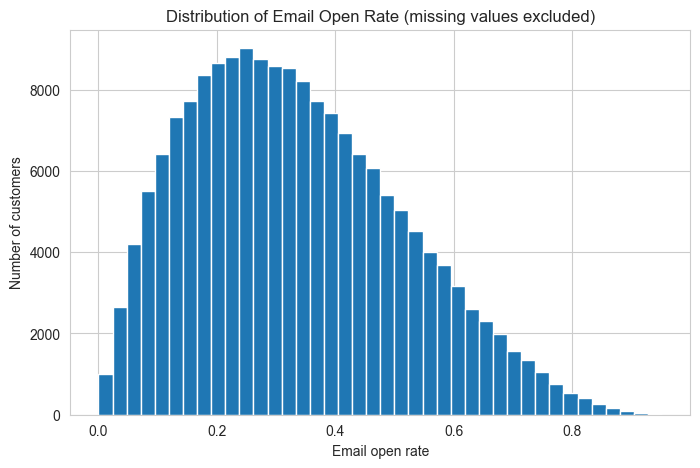

In [35]:
plt.figure(figsize=(8, 5))
# dropna() because email_open_rate has missing values
plt.hist(customers["email_open_rate"].dropna(), bins=40)
plt.title("Distribution of Email Open Rate (missing values excluded)")
plt.xlabel("Email open rate")
plt.ylabel("Number of customers")
plt.show()

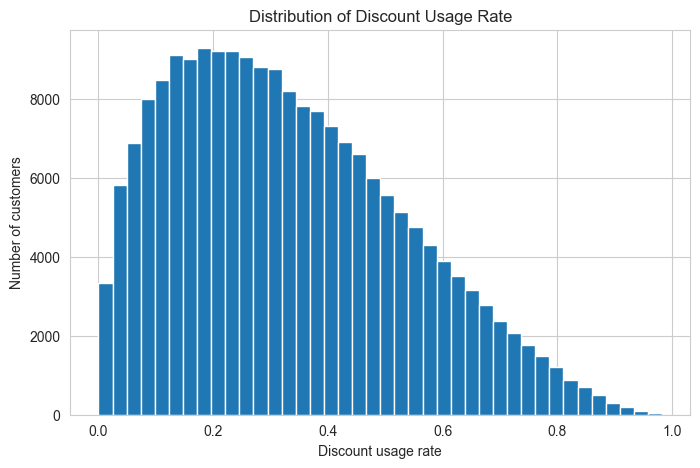

In [36]:
plt.figure(figsize=(8, 5))
plt.hist(customers["discount_usage_rate"], bins=40)
plt.title("Distribution of Discount Usage Rate")
plt.xlabel("Discount usage rate")
plt.ylabel("Number of customers")
plt.show()

**What these charts show:** how the scores are spread. Tall bars on the left that get shorter to the right mean most customers have low values and only a few have high values.

### Findings – Rates 
- All three stay between 0 and 1 (check that the printed counts above are all 0).
- Means are about 0.29 (loyalty), 0.33 (email) and 0.33 (discount). The medians are lower than the means, so the charts lean to the right.
- Only `email_open_rate` has missing values: 22,746 (about 11.4%).

### Are the missing `email_open_rate` values random?
We compare customers whose email rate is missing with customers whose email rate is present. If the two groups look very different, the missing values have a pattern. We only look. We do not fill anything.

In [37]:
# Two small tables: rows where the email rate is empty, and rows where it is not empty
email_missing = customers[customers["email_open_rate"].isna()]
email_present = customers[customers["email_open_rate"].notna()]

print("Rows with missing email rate:", len(email_missing))

print("\nAverage loyalty score - missing group:", email_missing["loyalty_score"].mean())
print("Average loyalty score - present group:", email_present["loyalty_score"].mean())
print("Average discount rate - missing group:", email_missing["discount_usage_rate"].mean())
print("Average discount rate - present group:", email_present["discount_usage_rate"].mean())

print("\nTier shares - missing group:")
print(email_missing["customer_tier"].value_counts(normalize=True))
print("\nTier shares - present group:")
print(email_present["customer_tier"].value_counts(normalize=True))

Rows with missing email rate: 22746

Average loyalty score - missing group: 0.06379407368328498
Average loyalty score - present group: 0.31380654315276385
Average discount rate - missing group: 0.3313279566654569
Average discount rate - present group: 0.33260243191074657

Tier shares - missing group:
customer_tier
Platinum    0.252528
Silver      0.250330
Bronze      0.249099
Gold        0.248044
Name: proportion, dtype: float64

Tier shares - present group:
customer_tier
Platinum    0.251261
Gold        0.251035
Bronze      0.250849
Silver      0.246855
Name: proportion, dtype: float64


### Findings – Missing email rate (fill in after running)
- Write what you see here. Similar numbers = no obvious pattern.

### Credit limit
`credit_limit` is text like `$16,421`. We make a number version called `credit_num` by removing the `$` and the `,`.

In [38]:
# Remove "$" and "," from the text, then convert the text to numbers
credit_text = customers["credit_limit"].str.replace("$", "", regex=False)
credit_text = credit_text.str.replace(",", "", regex=False)
credit_num = pd.to_numeric(credit_text, errors="coerce")

print("Values that could not be converted:", credit_num.isna().sum())
print("Zero or negative values:", (credit_num <= 0).sum())
print(credit_num.describe())

Values that could not be converted: 0
Zero or negative values: 0
count    200000.000000
mean      10504.595990
std        5477.459292
min        1000.000000
25%        5762.000000
50%       10505.000000
75%       15241.000000
max       19999.000000
Name: credit_limit, dtype: float64


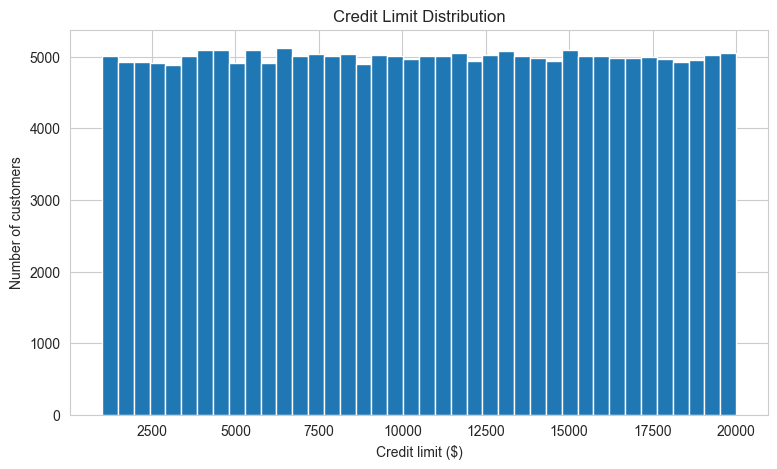

In [39]:
plt.figure(figsize=(9, 5))
plt.hist(credit_num.dropna(), bins=40)
plt.title("Credit Limit Distribution")
plt.xlabel("Credit limit ($)")
plt.ylabel("Number of customers")
plt.show()

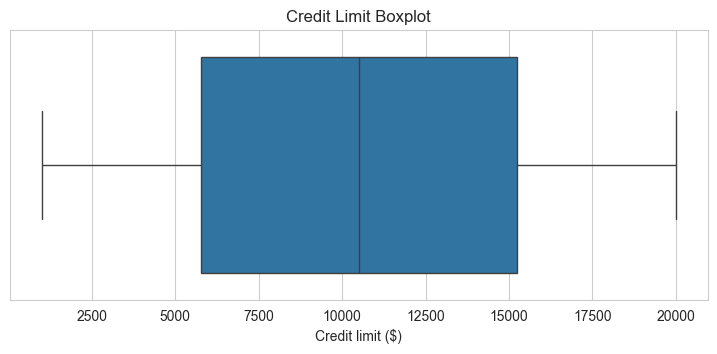

In [40]:
plt.figure(figsize=(9, 3.5))
sns.boxplot(x=credit_num.dropna())
plt.title("Credit Limit Boxplot")
plt.xlabel("Credit limit ($)")
plt.show()

In [41]:
# Average credit limit for each tier (a business check: higher tiers should have higher limits)
print(credit_num.groupby(customers["customer_tier"]).mean())

customer_tier
Bronze      10521.061680
Gold        10474.709268
Platinum    10526.231360
Silver      10496.208069
Name: credit_limit, dtype: float64


### Findings – Credit limit (fill in after running)
- Confirmed in Part 1: the values are text with `$` and commas, with 18,999 different values.
- After running, write the range (min and max), the shape of the histogram, and whether the tier averages are different. If all tiers have about the same average limit, tier and credit limit are not linked.

### Signup date
We convert `signup_date` to a real date in a new variable called `signup`.

In [42]:
signup = pd.to_datetime(customers["signup_date"], errors="coerce")

print("Dates that could not be read:", signup.isna().sum())
print("Earliest signup:", signup.min())
print("Latest signup:", signup.max())

# Number of signups in each month (to_period("M") turns a date into its month)
monthly_signups = signup.dt.to_period("M").value_counts().sort_index()
print(monthly_signups.head())

Dates that could not be read: 0
Earliest signup: 2022-01-01 00:00:00
Latest signup: 2024-09-26 00:00:00
signup_date
2022-01    6259
2022-02    5591
2022-03    6166
2022-04    6062
2022-05    6207
Freq: M, Name: count, dtype: int64


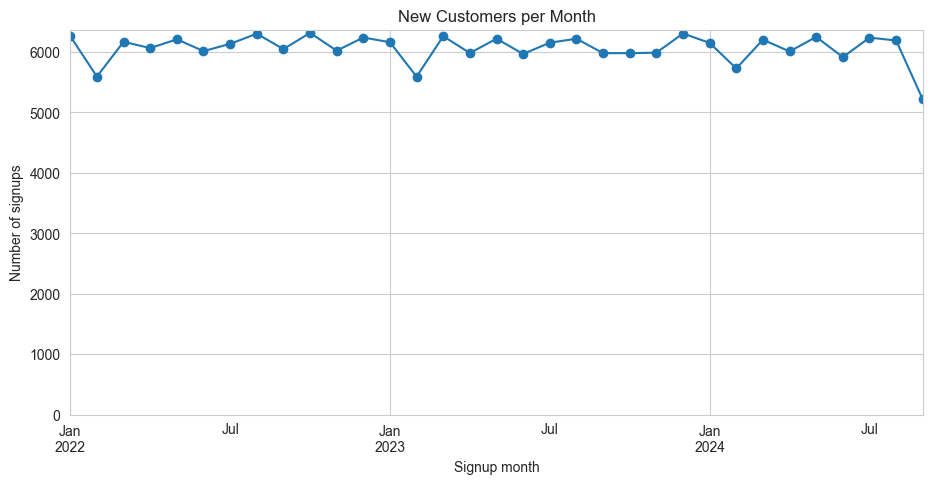

In [43]:
monthly_signups.plot(figsize=(11, 5), marker="o")
plt.title("New Customers per Month")
plt.xlabel("Signup month")
plt.ylabel("Number of signups")
# Start the Y axis at 0 so small ups and downs are not exaggerated
plt.ylim(bottom=0)
plt.show()

### Findings – Signup date 
- line chart showed 1,000 different dates with 233 to 241 signups on the busiest days, so signups look **even over time**. Check that the line is flat.
- Check that the last signup date is not later than the last transaction date (see section E).

### Referral code and region

In [44]:
print("Unique referral codes:", customers["referral_code"].nunique(), "out of", len(customers))

# value_counts() counts how often each code appears
code_counts = customers["referral_code"].value_counts()
print("Codes used by more than one customer:", (code_counts > 1).sum())

# All codes should start with REF_ and have the same length
print("All start with REF_ ?", customers["referral_code"].str.startswith("REF_").all())
print("Code lengths:")
print(customers["referral_code"].str.len().value_counts())

Unique referral codes: 179259 out of 200000
Codes used by more than one customer: 19270
All start with REF_ ? True
Code lengths:
referral_code
10    200000
Name: count, dtype: int64


In [45]:
# set() makes a list of different values. This finds customer regions that are NOT in geo_data
missing_regions = set(customers["region"]) - set(geo_data["geo_ip_region"])
print("Customer regions not found in geo_data:", len(missing_regions))

Customer regions not found in geo_data: 0


### Findings – Referral code and region (fill in after running)
- 179,259 unique codes for 200,000 customers (Part 1). If codes are random 6-digit numbers, about 181,000 different codes would be expected by chance, so the repeats are probably random collisions. **Question for the team:** should a referral code be unique per customer?
- We expect 0 missing regions. If it is not 0, the join to `geo_data` will lose rows.

### Correlations and the `noise_customer_*` columns
**Correlation** is a number between -1 and +1. It tells us whether two columns go up and down together. We want to see if the `noise_customer_*` columns relate to anything. We do **not** remove them.

In [46]:
noise_cols = ["noise_customer_0", "noise_customer_1", "noise_customer_2", "noise_customer_3", "noise_customer_4"]

# A small table with only numeric columns. .copy() makes a separate copy so customers is not changed
cust_num = customers[["loyalty_score", "email_open_rate", "discount_usage_rate", "avg_review_score"] + noise_cols].copy()
cust_num["age"] = age_num
cust_num["credit_limit"] = credit_num

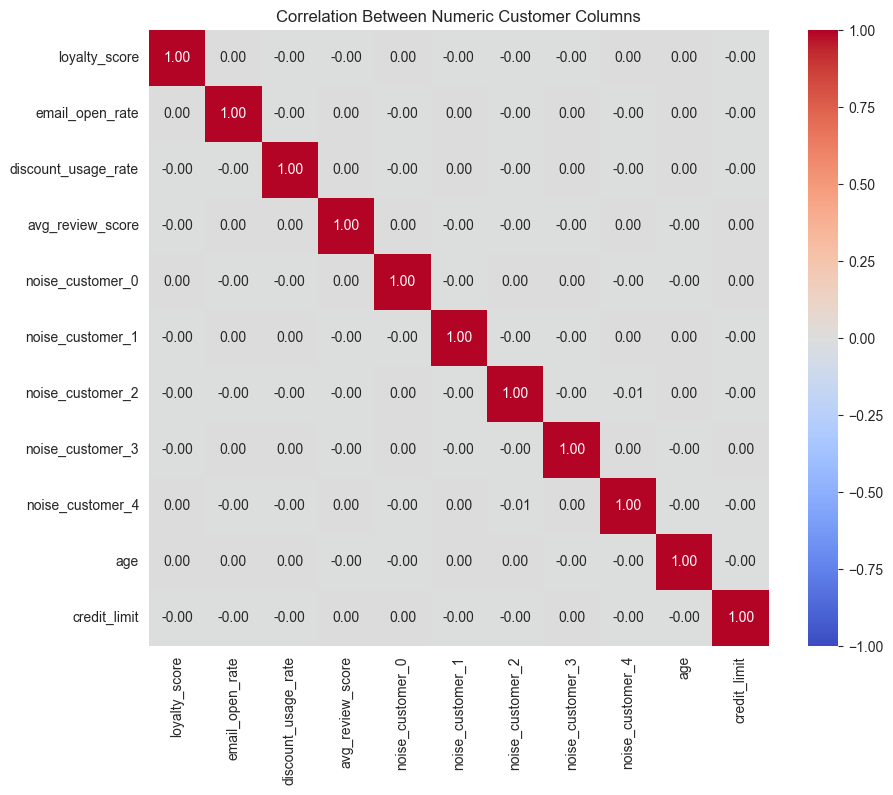

In [47]:
plt.figure(figsize=(10, 8))
# annot=True writes the numbers inside the squares
sns.heatmap(cust_num.corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Numeric Customer Columns")
plt.show()

### Findings – Correlations (fill in after running)
- The noise columns have an average of about 0 and a spread of about 1 (Part 1), like random numbers. If their squares are white, that supports the name "noise".
- **Do not drop them yet.** First check their link to the target in section F.

## geo_data analysis 
100 regions with income, urban ratio, internet penetration and a tier. We can join these to customers and sessions by region name.

In [48]:
print(geo_data.describe())
print("\nIs geo_ip_region unique?", geo_data["geo_ip_region"].is_unique)
print("\nRegions per tier:")
print(geo_data["region_tier"].value_counts())

       average_income  urban_ratio  internet_penetration
count      100.000000   100.000000            100.000000
mean     48442.302239     0.616034              0.758863
std      13622.526420     0.187294              0.140971
min      10703.823439     0.303290              0.507574
25%      40986.414943     0.456832              0.642996
50%      48095.655623     0.629801              0.767508
75%      56089.280780     0.751539              0.880337
max      77784.172768     0.940673              0.985126

Is geo_ip_region unique? True

Regions per tier:
region_tier
Tier1    41
Tier2    33
Tier3    26
Name: count, dtype: int64


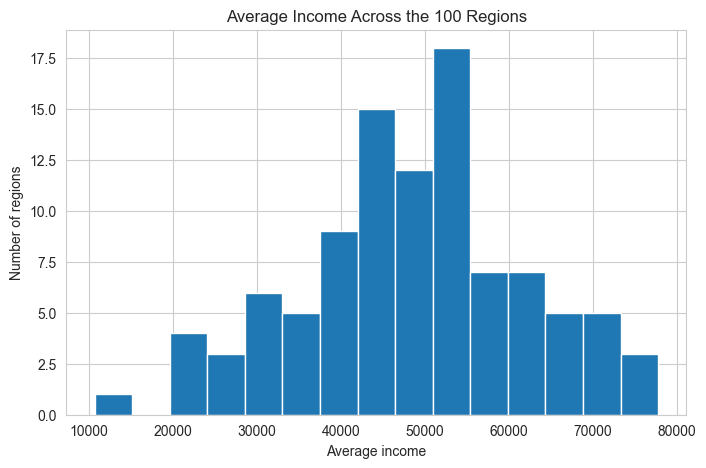

In [49]:
plt.figure(figsize=(8, 5))
plt.hist(geo_data["average_income"], bins=15)
plt.title("Average Income Across the 100 Regions")
plt.xlabel("Average income")
plt.ylabel("Number of regions")
plt.show()

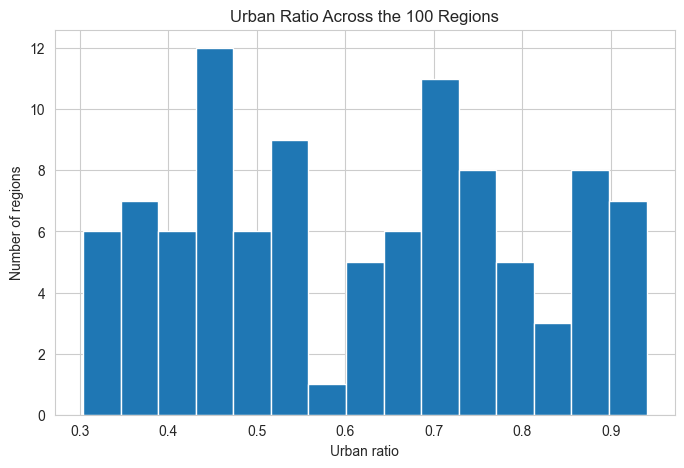

In [50]:
plt.figure(figsize=(8, 5))
plt.hist(geo_data["urban_ratio"], bins=15)
plt.title("Urban Ratio Across the 100 Regions")
plt.xlabel("Urban ratio")
plt.ylabel("Number of regions")
plt.show()

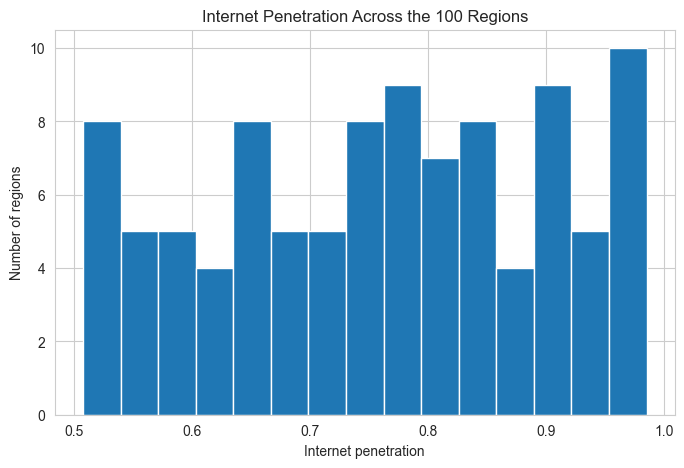

In [51]:
plt.figure(figsize=(8, 5))
plt.hist(geo_data["internet_penetration"], bins=15)
plt.title("Internet Penetration Across the 100 Regions")
plt.xlabel("Internet penetration")
plt.ylabel("Number of regions")
plt.show()

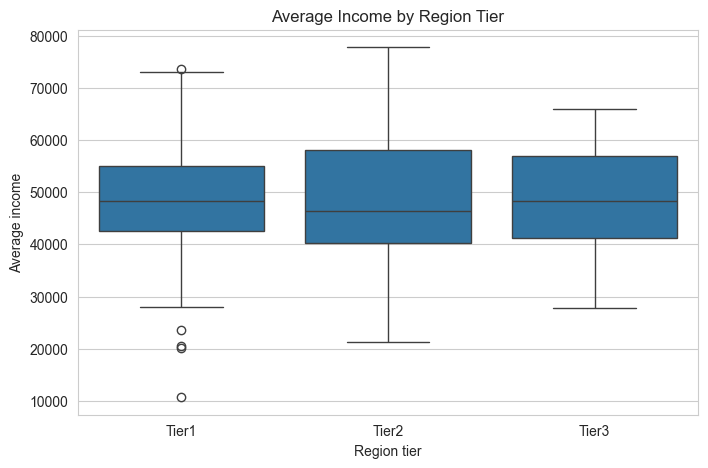

In [52]:
plt.figure(figsize=(8, 5))
sns.boxplot(x="region_tier", y="average_income", data=geo_data, order=["Tier1", "Tier2", "Tier3"])
plt.title("Average Income by Region Tier")
plt.xlabel("Region tier")
plt.ylabel("Average income")
plt.show()

In [53]:
# Average of each column for each tier
print(geo_data.groupby("region_tier")[["average_income", "urban_ratio", "internet_penetration"]].mean())

             average_income  urban_ratio  internet_penetration
region_tier                                                   
Tier1          48112.227052     0.599203              0.775518
Tier2          48470.526358     0.635406              0.769644
Tier3          48926.982497     0.617987              0.718916


**What the chart shows:** one box per tier. If Tier1 meant "richest", its box would sit clearly higher. Here all boxes sit at about the same height, so **tier does not follow income**. The dots are regions that are unusual compared with the others in the same tier.

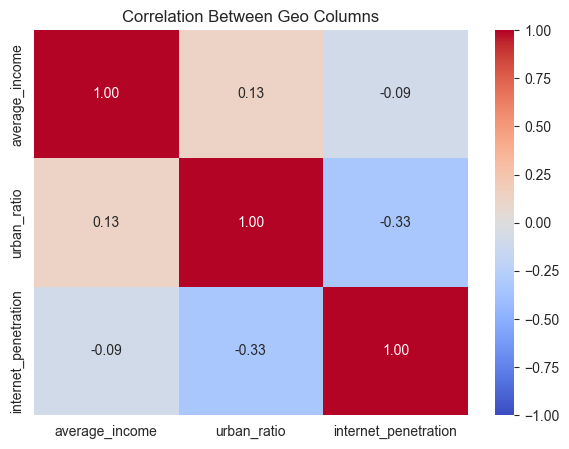

In [54]:
plt.figure(figsize=(7, 5))
sns.heatmap(geo_data[["average_income", "urban_ratio", "internet_penetration"]].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation Between Geo Columns")
plt.show()

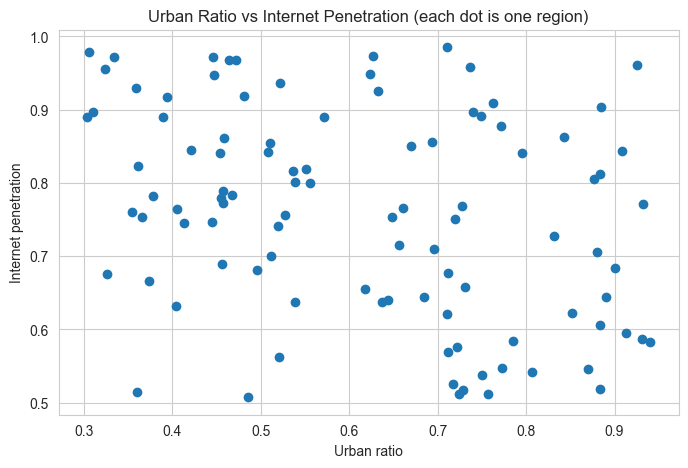

In [55]:
plt.figure(figsize=(8, 5))
plt.scatter(geo_data["urban_ratio"], geo_data["internet_penetration"])
plt.title("Urban Ratio vs Internet Penetration (each dot is one region)")
plt.xlabel("Urban ratio")
plt.ylabel("Internet penetration")
plt.show()

In [56]:
# IQR rule (the same method as Part 1) for average_income
q1 = geo_data["average_income"].quantile(0.25)
q3 = geo_data["average_income"].quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr
print("Lower bound:", lower, "| Upper bound:", upper)

# Show the regions outside the bounds
print(geo_data[(geo_data["average_income"] < lower) | (geo_data["average_income"] > upper)])

Lower bound: 18332.116186111623 | Upper bound: 78743.57953662252
   geo_ip_region  average_income  urban_ratio  internet_penetration  \
74     region_74    10703.823439     0.694179              0.855785   

   region_tier  
74       Tier1  


### Findings – geo_data (verified on the real file)
- 100 regions, `geo_ip_region` is unique, no missing values. The names are `region_0` to `region_99`, the same style as `customers["region"]`.
- Tiers: Tier1 = 41 regions, Tier2 = 33, Tier3 = 26.
- Average income: mean about 48,442, from 10,704 to 77,784, roughly bell-shaped. Urban ratio goes from 0.30 to 0.94. Internet penetration goes from 0.51 to 0.99.
- **`region_tier` does not follow income.** The average income is about 48,100 (Tier1), 48,500 (Tier2) and 48,900 (Tier3). Tier3 has a little lower internet penetration (0.72 compared with about 0.77).
- Urban ratio and internet penetration have a weak **negative** correlation (-0.33). We would normally expect a positive one, which is another hint that the values may be generated.
- Across all 100 regions only `region_74` is an outlier by the IQR rule (income 10,704). The tier boxplot shows a few more low dots in Tier1, but they are unusual only compared with the other Tier1 regions. These are statistical outliers, not proven mistakes. **Question for the team:** are these real poorer regions?

## marketing_campaigns analysis 
200 campaigns. `campaign_budget` and both dates are text, so we make number/date versions: `campaign_budget_num`, `start`, `end` and `duration_days`.

In [57]:
# Budget: remove "$" and ",", then convert to numbers
budget_text = marketing["campaign_budget"].str.replace("$", "", regex=False)
budget_text = budget_text.str.replace(",", "", regex=False)
campaign_budget_num = pd.to_numeric(budget_text, errors="coerce")

# Dates: convert text to real dates
start = pd.to_datetime(marketing["start_date"], errors="coerce")
end = pd.to_datetime(marketing["end_date"], errors="coerce")

# Duration in days (end minus start); .dt.days gives the number of days
duration_days = (end - start).dt.days

In [58]:
print("Is campaign_id unique?", marketing["campaign_id"].is_unique)
print("campaign_id from", marketing["campaign_id"].min(), "to", marketing["campaign_id"].max())
print("Budgets that could not be converted:", campaign_budget_num.isna().sum())
print("Dates that could not be read:", start.isna().sum() + end.isna().sum())
print("Campaigns that end on or before their start date:", (duration_days <= 0).sum())
print("First start date:", start.min(), "| Last end date:", end.max())
print("\nCampaigns per type:")
print(marketing["campaign_type"].value_counts())
print("\nBudget:")
print(campaign_budget_num.describe())
print("\nDuration in days:")
print(duration_days.describe())

Is campaign_id unique? True
campaign_id from 0 to 199
Budgets that could not be converted: 0
Dates that could not be read: 0
Campaigns that end on or before their start date: 0
First start date: 2022-01-01 00:00:00 | Last end date: 2023-04-21 00:00:00

Campaigns per type:
campaign_type
Display      52
Email        45
Search       38
Affiliate    33
Social       32
Name: count, dtype: int64

Budget:
count       200.000000
mean     248659.535000
std      141177.795983
min       11062.000000
25%      124653.000000
50%      257701.000000
75%      375711.000000
max      495450.000000
Name: campaign_budget, dtype: float64

Duration in days:
count    200.000000
mean      73.230000
std       25.728913
min       30.000000
25%       51.750000
50%       70.500000
75%       94.000000
max      119.000000
dtype: float64


In [59]:
# Do all target regions exist in geo_data?
print("Target regions not found in geo_data:", len(set(marketing["region_target"]) - set(geo_data["geo_ip_region"])))
print("Different regions targeted:", marketing["region_target"].nunique(), "out of", len(geo_data))
print("\nMost targeted regions:")
print(marketing["region_target"].value_counts().head())

Target regions not found in geo_data: 0
Different regions targeted: 85 out of 100

Most targeted regions:
region_target
region_50    6
region_96    6
region_74    5
region_69    5
region_39    5
Name: count, dtype: int64


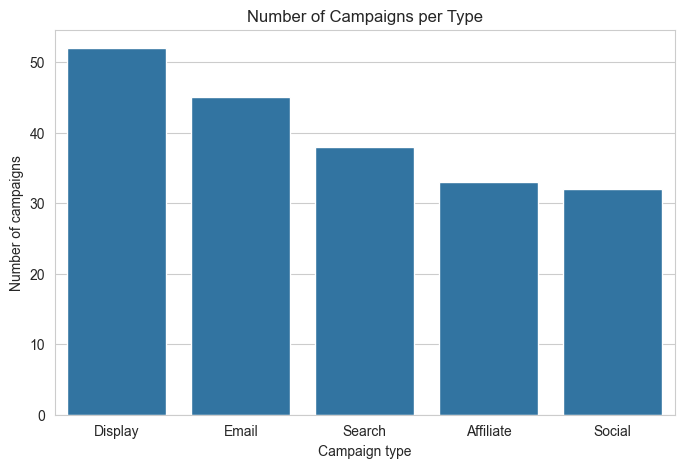

In [60]:
plt.figure(figsize=(8, 5))
sns.countplot(x=marketing["campaign_type"], order=marketing["campaign_type"].value_counts().index)
plt.title("Number of Campaigns per Type")
plt.xlabel("Campaign type")
plt.ylabel("Number of campaigns")
plt.show()

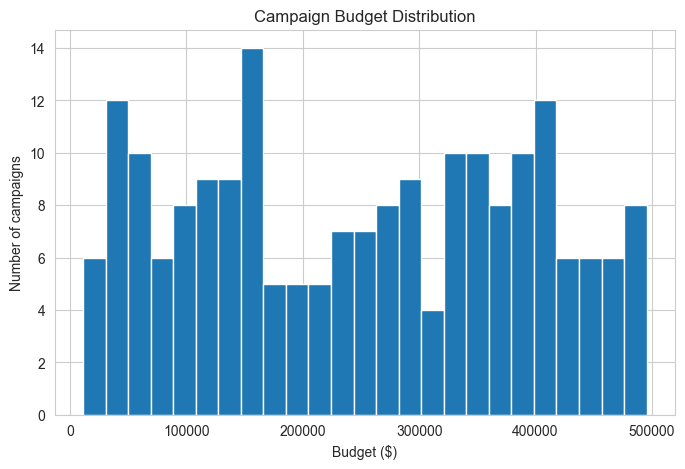

In [61]:
plt.figure(figsize=(8, 5))
plt.hist(campaign_budget_num, bins=25)
plt.title("Campaign Budget Distribution")
plt.xlabel("Budget ($)")
plt.ylabel("Number of campaigns")
plt.show()

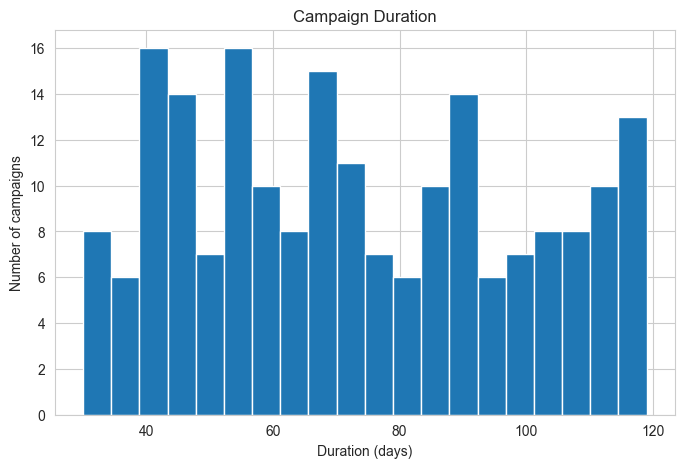

In [62]:
plt.figure(figsize=(8, 5))
plt.hist(duration_days, bins=20)
plt.title("Campaign Duration")
plt.xlabel("Duration (days)")
plt.ylabel("Number of campaigns")
plt.show()

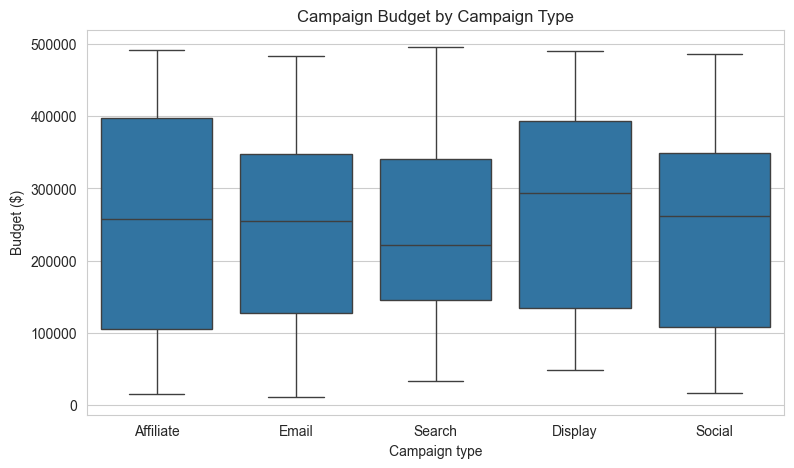

In [63]:
plt.figure(figsize=(9, 5))
sns.boxplot(x=marketing["campaign_type"], y=campaign_budget_num)
plt.title("Campaign Budget by Campaign Type")
plt.xlabel("Campaign type")
plt.ylabel("Budget ($)")
plt.show()

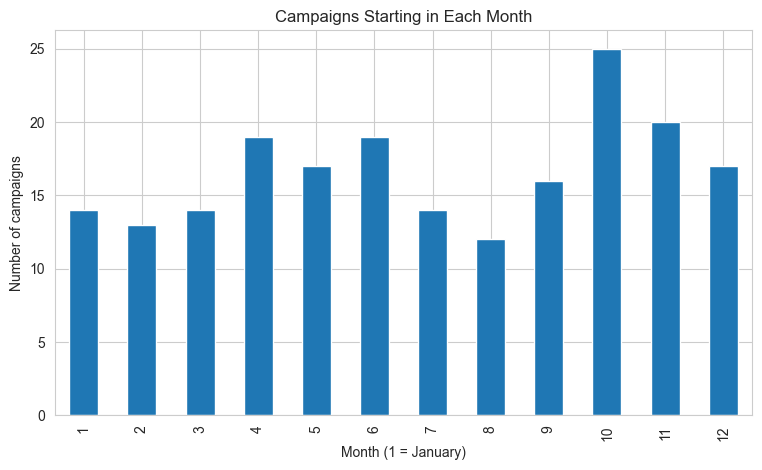

In [64]:
plt.figure(figsize=(9, 5))
# start.dt.month gives the month number (1-12); value_counts counts campaigns; sort_index orders months
start.dt.month.value_counts().sort_index().plot(kind="bar")
plt.title("Campaigns Starting in Each Month")
plt.xlabel("Month (1 = January)")
plt.ylabel("Number of campaigns")
plt.show()

**What these charts show:** campaign counts per type, how budgets and durations are spread, budget range per type, and which months campaigns start in.

### Findings – marketing_campaigns (verified on the real file)
- 200 campaigns, `campaign_id` is unique (0 to 199), no missing values, every budget and date converts correctly.
- Types: Display 52, Email 45, Search 38, Affiliate 33, Social 32.
- Budgets go from $11,062 to $495,450 (mean about $248,660). The histogram is **flat**, which is unusual for real budgets (usually many small and a few huge). The middle budget per type is similar (about $222,000 to $293,000).
- Duration is 30 to 119 days (mean 73). Every campaign ends after it starts.
- All campaigns **start in 2022**. 47 end in 2023, the last on 2023-04-21. October is the busiest start month (25 campaigns).
- All target regions exist in `geo_data`. 85 of the 100 regions are targeted, some up to 6 times, so campaigns can overlap in one region.
- **Potential issue:** signup dates go into 2024 (seen in Part 1), but campaigns only cover 2022 to April 2023. Check the session dates in section D.

In [65]:
print("Rows:", len(sessions))
print("Is session_id unique?", sessions["session_id"].is_unique)

# Convert the text timestamps to real date-times (this can take some seconds on 2 million rows)
session_ts = pd.to_datetime(sessions["session_timestamp"], errors="coerce")
print("Timestamps that could not be read:", session_ts.isna().sum())
print("First session:", session_ts.min())
print("Last session:", session_ts.max())

# A random sample used only for charts
sessions_sample = sessions.sample(100000, random_state=42)

Rows: 2000000
Is session_id unique? True
Timestamps that could not be read: 0
First session: 2022-01-01 00:00:00
Last session: 2024-09-26 00:00:00


In [66]:
print(sessions[["session_duration", "pages_viewed", "cart_additions"]].describe())

       session_duration  pages_viewed  cart_additions
count      2.000000e+06  1.900000e+06    2.000000e+06
mean       4.767312e+02  6.003728e+00    1.999042e+00
std        1.183433e+03  2.449721e+00    1.414129e+00
min        1.532914e-04  0.000000e+00    0.000000e+00
25%        1.164294e+02  4.000000e+00    1.000000e+00
50%        2.815162e+02  6.000000e+00    2.000000e+00
75%        5.664990e+02  8.000000e+00    3.000000e+00
max        8.243388e+04  2.100000e+01    1.300000e+01


In [67]:
print("Negative durations:", (sessions["session_duration"] < 0).sum())
print("Zero durations:", (sessions["session_duration"] == 0).sum())
print("Negative pages:", (sessions["pages_viewed"] < 0).sum())
print("Zero pages:", (sessions["pages_viewed"] == 0).sum())
print("Missing pages_viewed:", sessions["pages_viewed"].isna().sum())
print("Share missing:", sessions["pages_viewed"].isna().mean())

# % 1 gives the decimal part. Pages should be whole numbers, so we expect 0 here
print("pages_viewed with decimals:", (sessions["pages_viewed"].dropna() % 1 != 0).sum())

Negative durations: 0
Zero durations: 0
Negative pages: 0
Zero pages: 4730
Missing pages_viewed: 100000
Share missing: 0.05
pages_viewed with decimals: 0


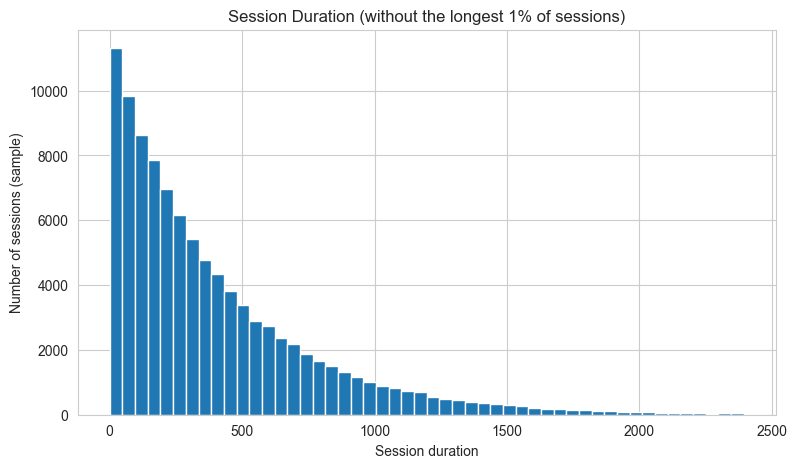

In [68]:
# For the chart only: keep sessions shorter than the 99th percentile, so a few huge values do not squash the chart
limit = sessions_sample["session_duration"].quantile(0.99)
duration_small = sessions_sample[sessions_sample["session_duration"] < limit]["session_duration"]

plt.figure(figsize=(9, 5))
plt.hist(duration_small, bins=50)
plt.title("Session Duration (without the longest 1% of sessions)")
plt.xlabel("Session duration")
plt.ylabel("Number of sessions (sample)")
plt.show()

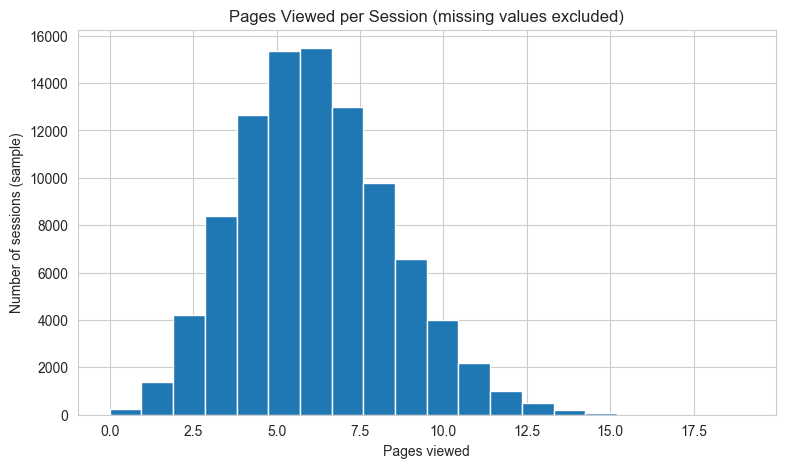

In [69]:
plt.figure(figsize=(9, 5))
plt.hist(sessions_sample["pages_viewed"].dropna(), bins=20)
plt.title("Pages Viewed per Session (missing values excluded)")
plt.xlabel("Pages viewed")
plt.ylabel("Number of sessions (sample)")
plt.show()

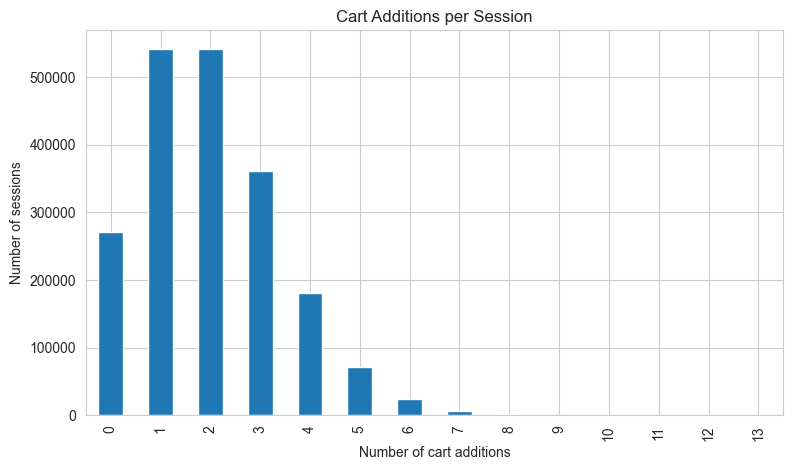

In [70]:
plt.figure(figsize=(9, 5))
# Count sessions for each number of cart additions (first 15 values only)
sessions["cart_additions"].value_counts().sort_index().head(15).plot(kind="bar")
plt.title("Cart Additions per Session")
plt.xlabel("Number of cart additions")
plt.ylabel("Number of sessions")
plt.show()

In [71]:
print(sessions["bounce_flag"].value_counts(dropna=False))

bounce_flag
0        334387
No       333380
TRUE     333276
1        333270
FALSE    332945
Yes      332742
Name: count, dtype: int64


In [72]:
# Logic check: a bounce means the visitor left quickly. These averages should be small for bounced sessions
print(sessions.groupby("bounce_flag")[["session_duration", "pages_viewed", "cart_additions"]].mean())

             session_duration  pages_viewed  cart_additions
bounce_flag                                                
0                  475.964559      6.010523        2.001944
1                  477.771243      5.998095        1.998833
FALSE              475.639884      6.007026        1.998423
No                 475.100047      6.003275        1.993998
TRUE               479.553713      6.001377        2.001221
Yes                476.359454      6.002046        1.999826


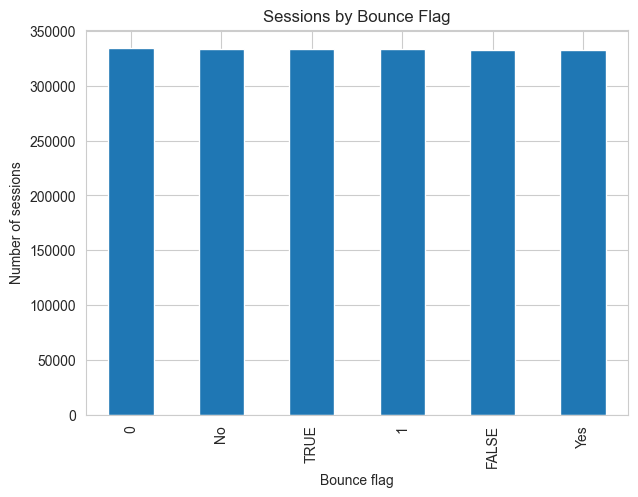

In [73]:
plt.figure(figsize=(7, 5))
sessions["bounce_flag"].value_counts().plot(kind="bar")
plt.title("Sessions by Bounce Flag")
plt.xlabel("Bounce flag")
plt.ylabel("Number of sessions")
plt.show()

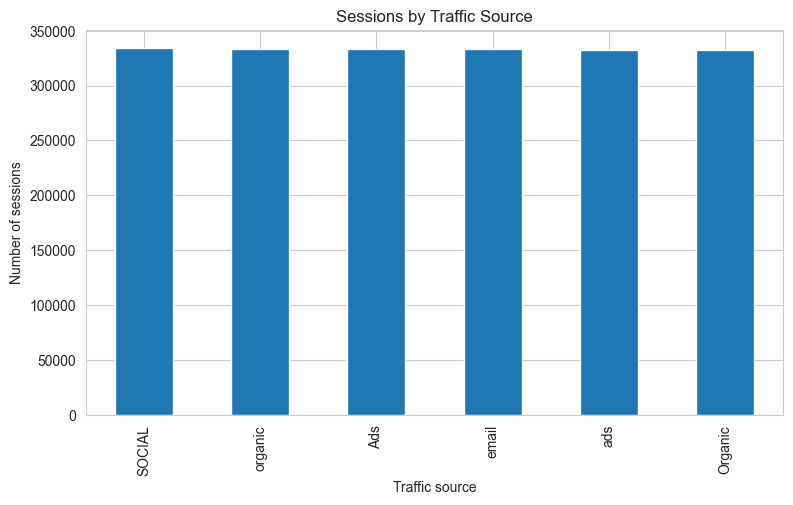

In [74]:
plt.figure(figsize=(9, 5))
sessions["traffic_source"].value_counts().plot(kind="bar")
plt.title("Sessions by Traffic Source")
plt.xlabel("Traffic source")
plt.ylabel("Number of sessions")
plt.show()

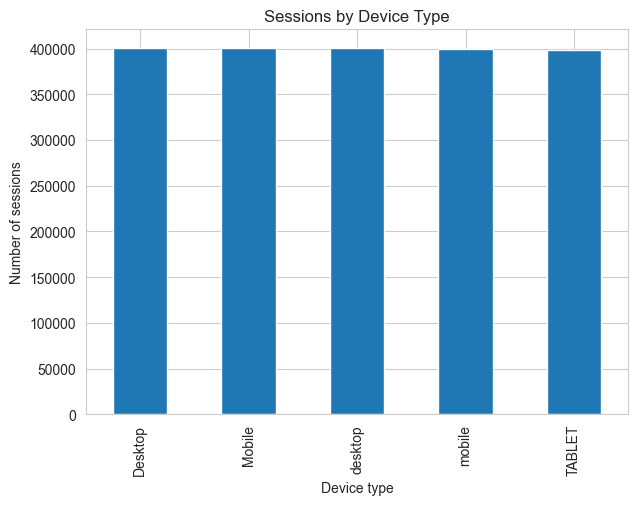

In [75]:
plt.figure(figsize=(7, 5))
sessions["device_type"].value_counts().plot(kind="bar")
plt.title("Sessions by Device Type")
plt.xlabel("Device type")
plt.ylabel("Number of sessions")
plt.show()

In [76]:
missing_pages = sessions[sessions["pages_viewed"].isna()]

print("Device type - rows with missing pages_viewed:")
print(missing_pages["device_type"].value_counts(normalize=True))
print("\nDevice type - all rows:")
print(sessions["device_type"].value_counts(normalize=True))

print("\nTraffic source - rows with missing pages_viewed:")
print(missing_pages["traffic_source"].value_counts(normalize=True))
print("\nTraffic source - all rows:")
print(sessions["traffic_source"].value_counts(normalize=True))

Device type - rows with missing pages_viewed:
device_type
desktop    0.20179
Desktop    0.20093
mobile     0.19947
TABLET     0.19906
Mobile     0.19875
Name: proportion, dtype: float64

Device type - all rows:
device_type
Desktop    0.200469
Mobile     0.200339
desktop    0.200205
mobile     0.199843
TABLET     0.199145
Name: proportion, dtype: float64

Traffic source - rows with missing pages_viewed:
traffic_source
SOCIAL     0.16842
ads        0.16836
email      0.16619
Ads        0.16601
Organic    0.16572
organic    0.16530
Name: proportion, dtype: float64

Traffic source - all rows:
traffic_source
SOCIAL     0.166957
organic    0.166847
Ads        0.166828
email      0.166774
ads        0.166319
Organic    0.166275
Name: proportion, dtype: float64


In [77]:
# Do the links to other tables work?
# isin() checks if a value exists in another column; ~ means "not"
bad_campaigns = ~sessions["campaign_id"].isin(marketing["campaign_id"])
print("Sessions with a campaign_id not in marketing:", bad_campaigns.sum())
print("Those campaign_id values:")
print(sessions[bad_campaigns]["campaign_id"].value_counts().head())

print("\nSessions with a customer_id not in customers:", (~sessions["customer_id"].isin(customers["customer_id"])).sum())
print("Sessions with a geo_ip_region not in geo_data:", (~sessions["geo_ip_region"].isin(geo_data["geo_ip_region"])).sum())

print("\nCustomers with at least one session:", sessions["customer_id"].nunique(), "out of", len(customers))
print("Sessions per customer:")
print(sessions["customer_id"].value_counts().describe())

Sessions with a campaign_id not in marketing: 0
Those campaign_id values:
Series([], Name: count, dtype: int64)

Sessions with a customer_id not in customers: 0
Sessions with a geo_ip_region not in geo_data: 0

Customers with at least one session: 199990 out of 200000
Sessions per customer:
count    199990.000000
mean         10.000500
std           3.159235
min           1.000000
25%           8.000000
50%          10.000000
75%          12.000000
max          27.000000
Name: count, dtype: float64


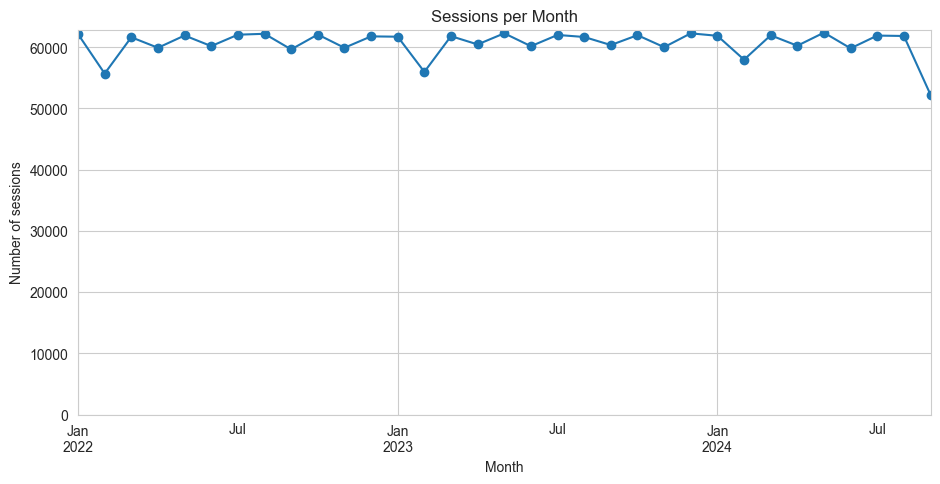

In [78]:
# Sessions in each month
monthly_sessions = session_ts.dt.to_period("M").value_counts().sort_index()

monthly_sessions.plot(figsize=(11, 5), marker="o")
plt.title("Sessions per Month")
plt.xlabel("Month")
plt.ylabel("Number of sessions")
plt.ylim(bottom=0)
plt.show()

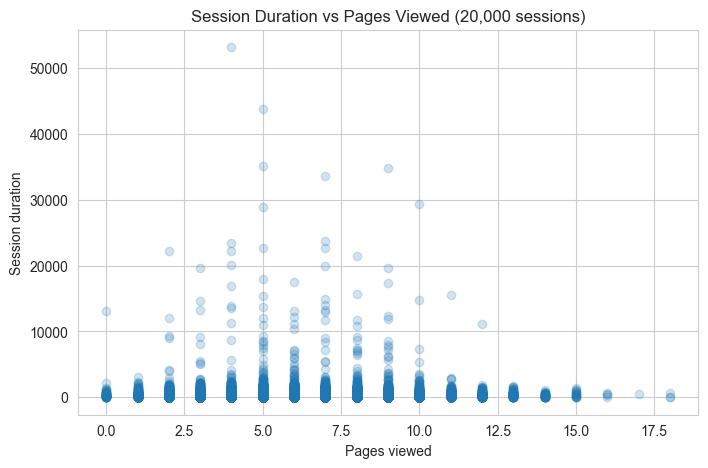

In [80]:
small_sample = sessions_sample.sample(20000, random_state=1)

plt.figure(figsize=(8, 5))
plt.scatter(small_sample["pages_viewed"], small_sample["session_duration"], alpha=0.2)
plt.title("Session Duration vs Pages Viewed (20,000 sessions)")
plt.xlabel("Pages viewed")
plt.ylabel("Session duration")
plt.show()

### Findings – sessions 
-  2,000,000 rows, no duplicate rows, `pages_viewed` has **100,000 missing values (exactly 5.0%)**. A round number like this suggests the gaps may have been added on purpose. `bounce_flag` is stored as text.
- After running, write down:
  1. Is `session_id` unique?
  2. The date range of the sessions. Do they go past April 2023, when the last campaign ends?
  3. Are there negative or extreme durations or pages?
  4. Which values does `bounce_flag` have? Do bounced sessions behave as expected?
  5. Are the missing `pages_viewed` values spread like all rows?
  6. How many `campaign_id`, `customer_id` and region values have no match? One value repeated many times (like -1) often means "no campaign".

##  transactions analysis 
`order_value`, `discount_applied` and `high_value_flag` are stored as text. First we look at how the text looks. Then we make number versions.

In [81]:
print("Rows:", len(transactions))
print("Is transaction_id unique?", transactions["transaction_id"].is_unique)
print(transactions[["order_value", "discount_applied", "high_value_flag"]].head(8))

Rows: 500000
Is transaction_id unique? True
  order_value discount_applied high_value_flag
0      $20.39                1              No
1     $181.53             TRUE              No
2     $107.92            FALSE              No
3     $130.47             TRUE              No
4     $126.98                0              No
5      $25.33                1              No
6      $47.72             TRUE              No
7      $80.53              Yes              No


In [82]:
print("discount_applied - most common values:")
print(transactions["discount_applied"].value_counts(dropna=False).head(10))
print("\nhigh_value_flag values:")
print(transactions["high_value_flag"].value_counts(dropna=False))

discount_applied - most common values:
discount_applied
1        83715
FALSE    83327
No       83326
Yes      83230
0        83220
TRUE     83182
Name: count, dtype: int64

high_value_flag values:
high_value_flag
No     400246
Yes     99754
Name: count, dtype: int64


In [83]:
# Make number versions. astype(str) makes sure we work with text; we remove "$" "," and "%"
order_text = transactions["order_value"].astype(str).str.replace("$", "", regex=False)
order_text = order_text.str.replace(",", "", regex=False)
order_value_num = pd.to_numeric(order_text, errors="coerce")

discount_text = transactions["discount_applied"].astype(str).str.replace("%", "", regex=False)
discount_num = pd.to_numeric(discount_text, errors="coerce")

print("order_value not converted:", order_value_num.isna().sum())
print("discount_applied not converted:", discount_num.isna().sum())
# If some order values were not converted, look at what they are
print(transactions[order_value_num.isna()]["order_value"].value_counts().head())

order_value not converted: 0
discount_applied not converted: 333065
Series([], Name: count, dtype: int64)


In [84]:
print(order_value_num.describe())
print("Zero or negative order values:", (order_value_num <= 0).sum())
print("\nitems_count:")
print(transactions["items_count"].describe())
print("items_count zero or negative:", (transactions["items_count"] <= 0).sum())

count    500000.000000
mean        120.032834
std         120.264645
min           0.000000
25%          34.420000
50%          83.080000
75%         166.390000
max        1670.020000
Name: order_value, dtype: float64
Zero or negative order values: 21

items_count:
count    500000.000000
mean          2.998380
std           1.734295
min           0.000000
25%           2.000000
50%           3.000000
75%           4.000000
max          14.000000
Name: items_count, dtype: float64
items_count zero or negative: 25059


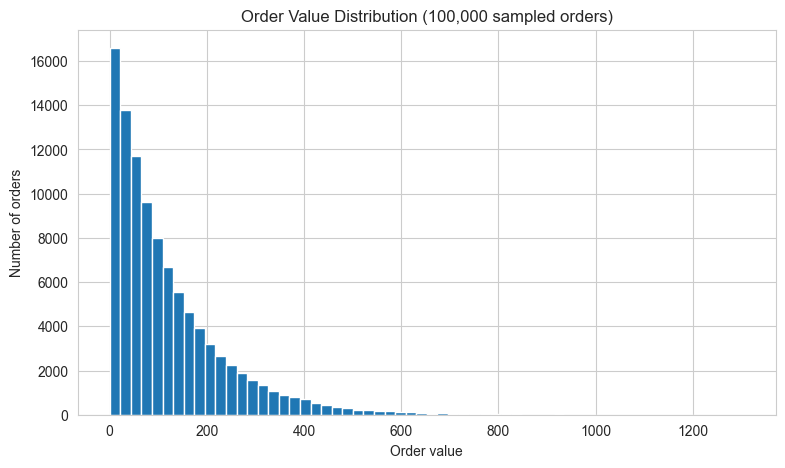

In [85]:
# Charts use a random sample of 100,000 orders (random_state makes it repeatable)
order_sample = order_value_num.sample(100000, random_state=42)

plt.figure(figsize=(9, 5))
plt.hist(order_sample.dropna(), bins=60)
plt.title("Order Value Distribution (100,000 sampled orders)")
plt.xlabel("Order value")
plt.ylabel("Number of orders")
plt.show()

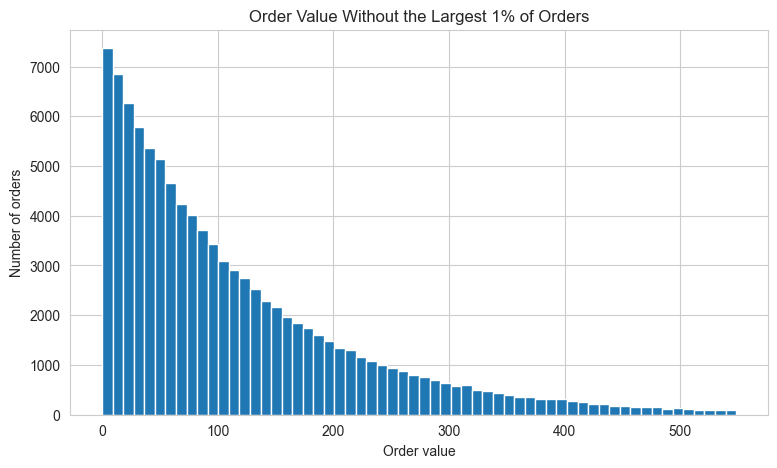

In [86]:
# Same chart without the largest 1% of orders, so the main shape is easier to see
limit_order = order_sample.quantile(0.99)
order_small = order_sample[order_sample < limit_order]

plt.figure(figsize=(9, 5))
plt.hist(order_small, bins=60)
plt.title("Order Value Without the Largest 1% of Orders")
plt.xlabel("Order value")
plt.ylabel("Number of orders")
plt.show()

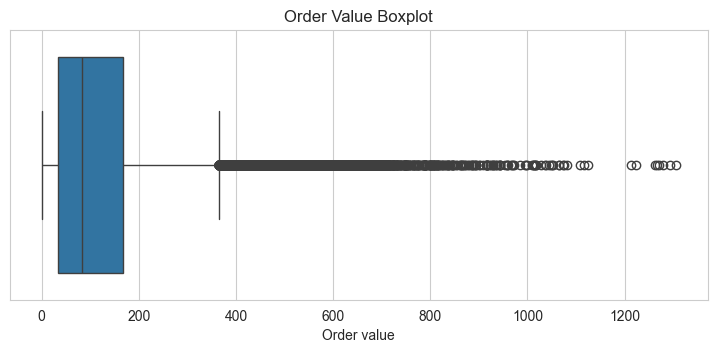

In [87]:
plt.figure(figsize=(9, 3.5))
sns.boxplot(x=order_sample.dropna())
plt.title("Order Value Boxplot")
plt.xlabel("Order value")
plt.show()

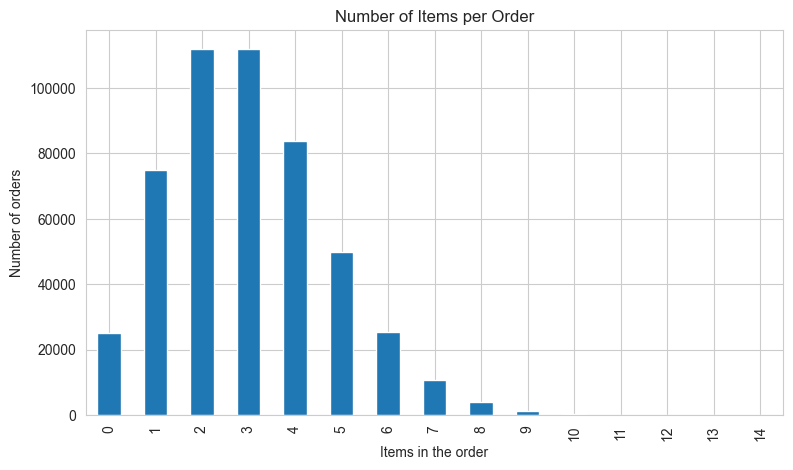

In [88]:
plt.figure(figsize=(9, 5))
transactions["items_count"].value_counts().sort_index().head(20).plot(kind="bar")
plt.title("Number of Items per Order")
plt.xlabel("Items in the order")
plt.ylabel("Number of orders")
plt.show()

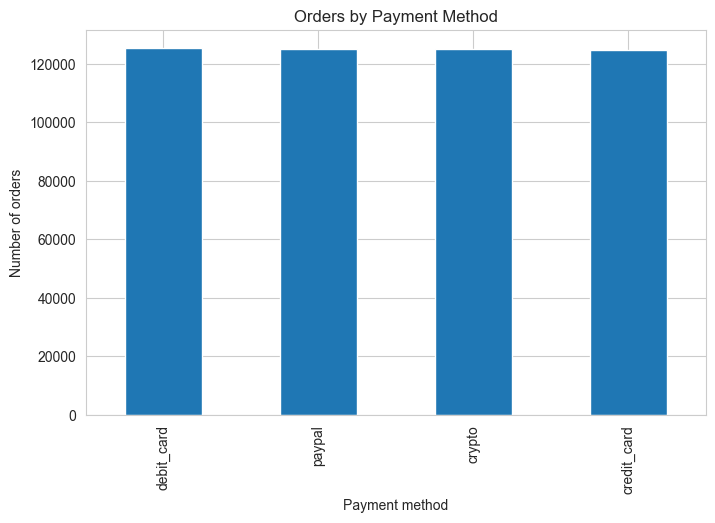

In [89]:
plt.figure(figsize=(8, 5))
transactions["payment_method"].value_counts().plot(kind="bar")
plt.title("Orders by Payment Method")
plt.xlabel("Payment method")
plt.ylabel("Number of orders")
plt.show()

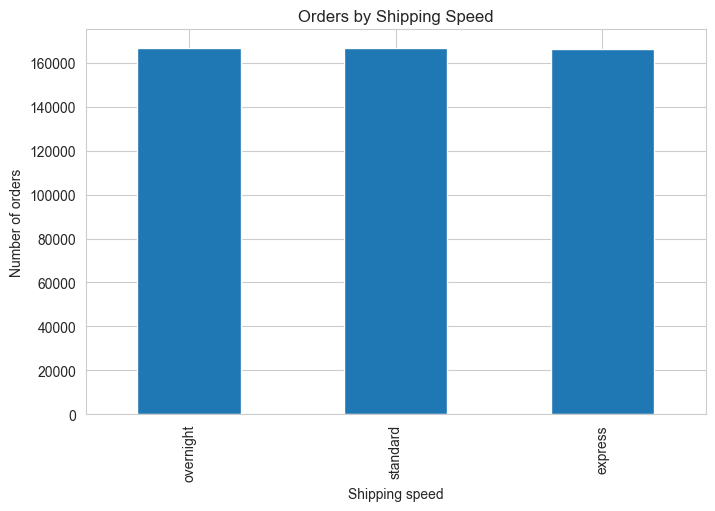

In [90]:
plt.figure(figsize=(8, 5))
transactions["shipping_speed"].value_counts().plot(kind="bar")
plt.title("Orders by Shipping Speed")
plt.xlabel("Shipping speed")
plt.ylabel("Number of orders")
plt.show()

In [91]:
print(transactions["payment_method"].value_counts(normalize=True))
print(transactions["shipping_speed"].value_counts(normalize=True))

payment_method
debit_card     0.250570
paypal         0.250148
crypto         0.249964
credit_card    0.249318
Name: proportion, dtype: float64
shipping_speed
overnight    0.333692
standard     0.333502
express      0.332806
Name: proportion, dtype: float64


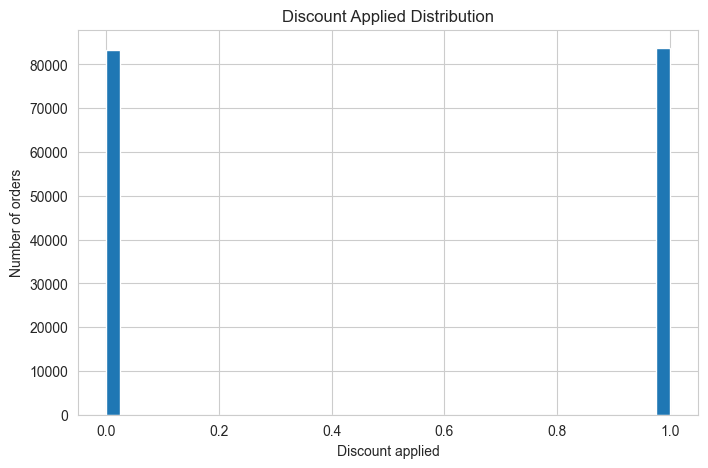

In [92]:
# Run this chart only if discount_applied was converted to numbers (check "discount_applied not converted" above)
plt.figure(figsize=(8, 5))
plt.hist(discount_num.dropna(), bins=40)
plt.title("Discount Applied Distribution")
plt.xlabel("Discount applied")
plt.ylabel("Number of orders")
plt.show()

In [93]:
# Which order values does each high_value_flag value cover?
# groupby() splits the orders by flag; agg() calculates min, max and mean for each group
print(order_value_num.groupby(transactions["high_value_flag"]).agg(["min", "max", "mean", "count"]))

                 min      max        mean   count
high_value_flag                                  
No               0.0  1669.05  120.119662  400246
Yes              0.0  1670.02  119.684448   99754


In [94]:
tx_ts = pd.to_datetime(transactions["transaction_timestamp"], errors="coerce")
print("Timestamps that could not be read:", tx_ts.isna().sum())
print("First order:", tx_ts.min())
print("Last order:", tx_ts.max())

monthly_orders = tx_ts.dt.to_period("M").value_counts().sort_index()
monthly_money = order_value_num.groupby(tx_ts.dt.to_period("M")).sum()

Timestamps that could not be read: 0
First order: 2022-01-01 00:00:00
Last order: 2024-09-26 00:00:00


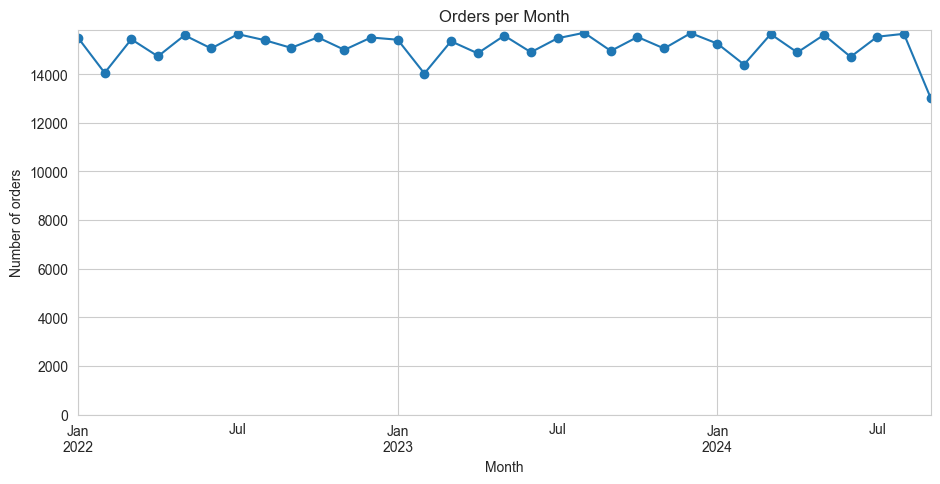

In [95]:
monthly_orders.plot(figsize=(11, 5), marker="o")
plt.title("Orders per Month")
plt.xlabel("Month")
plt.ylabel("Number of orders")
plt.ylim(bottom=0)
plt.show()

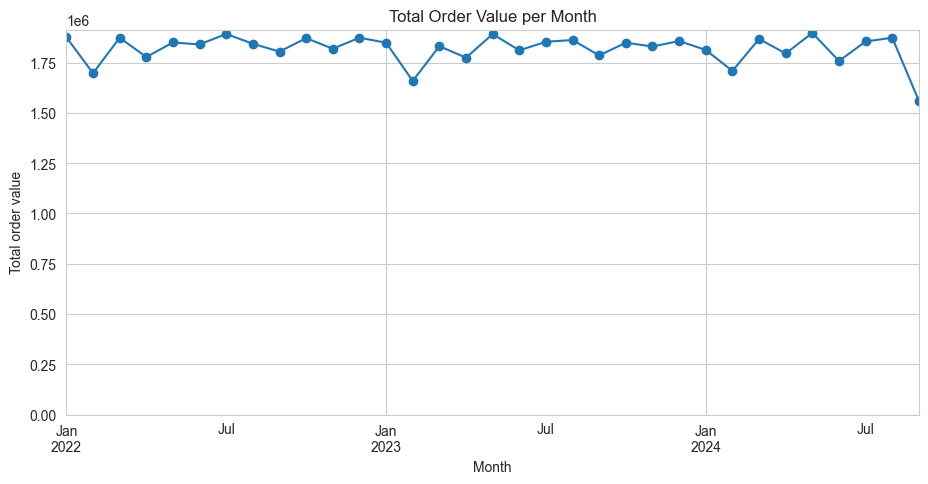

In [96]:
monthly_money.plot(figsize=(11, 5), marker="o")
plt.title("Total Order Value per Month")
plt.xlabel("Month")
plt.ylabel("Total order value")
plt.ylim(bottom=0)
plt.show()

In [97]:
# Do the links to customers work?
print("Orders with a customer_id not in customers:", (~transactions["customer_id"].isin(customers["customer_id"])).sum())
print("Customers with at least one order:", transactions["customer_id"].nunique(), "out of", len(customers))
print("Orders per customer:")
print(transactions["customer_id"].value_counts().describe())

Orders with a customer_id not in customers: 0
Customers with at least one order: 183541 out of 200000
Orders per customer:
count    183541.000000
mean          2.724187
std           1.453130
min           1.000000
25%           2.000000
50%           2.000000
75%           4.000000
max          12.000000
Name: count, dtype: float64


In [98]:
# Potential issue: orders placed BEFORE the customer signed up.
# merge() adds each customer's signup date next to each order (matching on customer_id)
tx_check = transactions[["customer_id", "transaction_timestamp"]].merge(
    customers[["customer_id", "signup_date"]], on="customer_id", how="left")

order_time = pd.to_datetime(tx_check["transaction_timestamp"], errors="coerce")
signup_time = pd.to_datetime(tx_check["signup_date"], errors="coerce")

print("Orders placed before the customer's signup date:", (order_time < signup_time).sum())

Orders placed before the customer's signup date: 249377


### Findings – transactions 
- 500,000 rows, no missing values, no duplicate rows. `order_value`, `discount_applied`, `shipping_speed` and `high_value_flag` are stored as text. `noise_trans_0` and `noise_trans_1` are numeric columns.
- After running, write down:
  1. The text format of `order_value` and `discount_applied`, and how many values could not be converted.
  2. The smallest, middle and largest order value. Are there zero or negative orders?
  3. The rule behind `high_value_flag`.
  4. The share of each payment method and shipping speed.
  5. The date range of the orders.
  6. Orders placed before signup, and customers who never ordered.

## Train, test and sample_submission 
We check class balance and ID overlap. **Why:** these checks protect us from *data leakage* (information from the test set, or from the future, leaking into model training).

In [99]:
print("train:", train.shape, "| test:", test.shape, "| sample_submission:", sample_submission.shape)
print("Is train customer_id unique?", train["customer_id"].is_unique)
print("Is test customer_id unique?", test["customer_id"].is_unique)

print("\nTarget counts:")
print(train["target"].value_counts())
print("\nTarget shares:")
print(train["target"].value_counts(normalize=True))

train: (160000, 2) | test: (40000, 1) | sample_submission: (40000, 2)
Is train customer_id unique? True
Is test customer_id unique? True

Target counts:
target
0    127514
1     32486
Name: count, dtype: int64

Target shares:
target
0    0.796963
1    0.203038
Name: proportion, dtype: float64


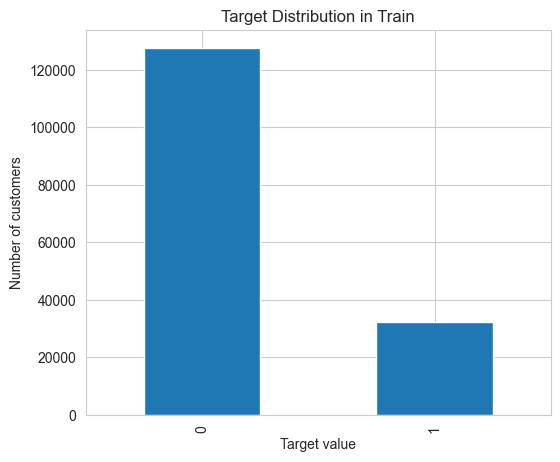

In [100]:
plt.figure(figsize=(6, 5))
train["target"].value_counts().sort_index().plot(kind="bar")
plt.title("Target Distribution in Train")
plt.xlabel("Target value")
plt.ylabel("Number of customers")
plt.show()

**What this chart shows:** how many train customers have target 0 and target 1. The left bar is about four times taller. This is called **class imbalance**.

In [101]:
# set() turns a column into a collection of different values. & means "in both"
train_ids = set(train["customer_id"])
test_ids = set(test["customer_id"])

print("IDs in both train and test:", len(train_ids & test_ids))
print("Different customers in train + test together:", len(train_ids | test_ids))
print("Together they are exactly IDs 0 to 199999:", (train_ids | test_ids) == set(range(200000)))

print("\nsample_submission has the same IDs as test:", set(sample_submission["customer_id"]) == test_ids)
print("Same order as test.csv:", (sample_submission["customer_id"].values == test["customer_id"].values).all())
print("sample_submission target values:")
print(sample_submission["target"].value_counts())

IDs in both train and test: 0
Different customers in train + test together: 200000
Together they are exactly IDs 0 to 199999: True

sample_submission has the same IDs as test: True
Same order as test.csv: True
sample_submission target values:
target
0    40000
Name: count, dtype: int64


In [102]:
# Do the train and test IDs exist in the customers table?
print("train IDs not in customers:", len(train_ids - set(customers["customer_id"])))
print("test IDs not in customers:", len(test_ids - set(customers["customer_id"])))

train IDs not in customers: 0
test IDs not in customers: 0


### Findings – train / test
- Train has 160,000 rows and test has 40,000 (an 80/20 split of 200,000 customers). IDs are unique in both.
- **The target is imbalanced:** 127,514 customers have target 0 (79.7%) and 32,486 have target 1 (20.3%), about 4 to 1. A model that always answers 0 would be right 79.7% of the time, so later we need metrics like recall, precision, F1 or AUC, not accuracy alone.
- **No overlap** between train and test. Together they contain exactly the 200,000 customers (IDs 0 to 199,999). The last cell should print 0 and 0 on your computer.
- `sample_submission.csv` has the same 40,000 IDs as test, in the same order, and every target is 0. It is only a format example, not real answers.
- **We do not know what target = 1 means.** It is not written in the files we have. Do not call it "churn" or "purchase" until the team confirms. The meaning also decides which columns could leak the answer.

### Which customer columns relate to the target? 
We join `train` to `customers` to compare target rates. **Why:** to learn which columns matter and whether the `noise_*` columns carry any signal. We use **train labels only**. The test file has no labels and is not used here.

In [103]:
# merge() puts the customer columns next to each train row (matching on customer_id)
train_cust = train.merge(customers, on="customer_id", how="left")

print("Rows in train:", len(train))
print("Rows after merge:", len(train_cust), "(should be the same)")
print("Train rows without a customer match:", train_cust["region"].isna().sum())

Rows in train: 160000
Rows after merge: 160000 (should be the same)
Train rows without a customer match: 0


customer_tier
Bronze      0.203486
Gold        0.198770
Platinum    0.206615
Silver      0.203282
Name: target, dtype: float64


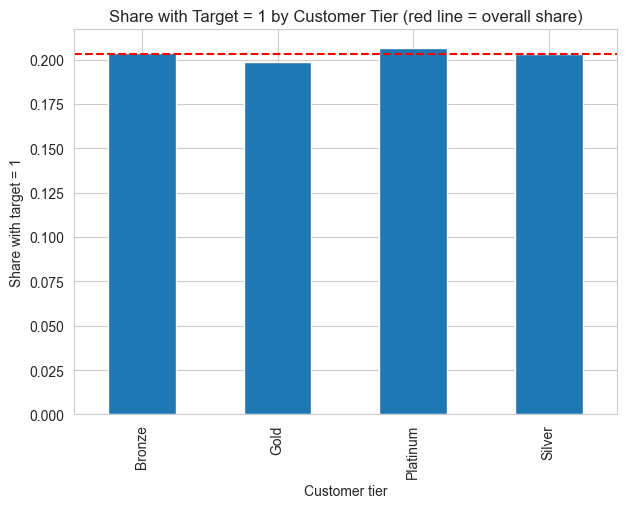

In [104]:
# Share of customers with target = 1 in each tier (the mean of 0/1 values is the share of ones)
rate_by_tier = train_cust.groupby("customer_tier")["target"].mean()
print(rate_by_tier)

plt.figure(figsize=(7, 5))
rate_by_tier.plot(kind="bar")
# The red dashed line is the overall share of target = 1
plt.axhline(train["target"].mean(), color="red", linestyle="--")
plt.title("Share with Target = 1 by Customer Tier (red line = overall share)")
plt.xlabel("Customer tier")
plt.ylabel("Share with target = 1")
plt.show()

country_code
DE    0.202581
FR    0.203984
IN    0.205332
UK    0.201646
US    0.203162
Name: target, dtype: float64


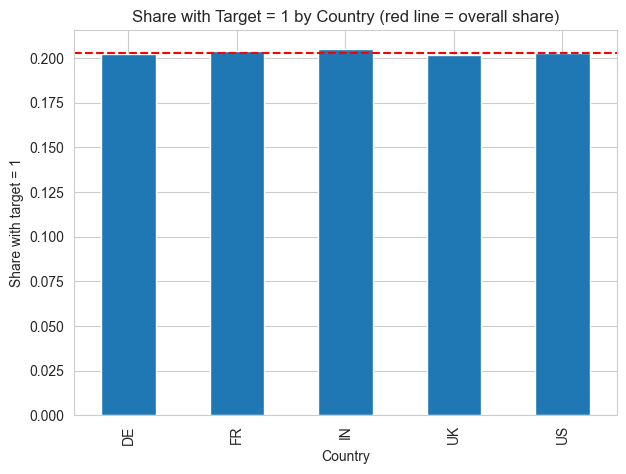

In [105]:
# Same idea for country. We re-use the unified spelling idea from A3
train_country = train_cust["country_code"].str.upper().str.replace(".", "", regex=False).replace("USA", "US")
rate_by_country = train_cust["target"].groupby(train_country).mean()
print(rate_by_country)

plt.figure(figsize=(7, 5))
rate_by_country.plot(kind="bar")
plt.axhline(train["target"].mean(), color="red", linestyle="--")
plt.title("Share with Target = 1 by Country (red line = overall share)")
plt.xlabel("Country")
plt.ylabel("Share with target = 1")
plt.show()

noise_customer_4      -0.001874
noise_customer_0      -0.001481
noise_customer_2      -0.000569
noise_customer_3       0.001860
email_open_rate        0.001979
avg_review_score       0.002335
noise_customer_1       0.004363
discount_usage_rate    0.078504
loyalty_score          0.094473
Name: target, dtype: float64


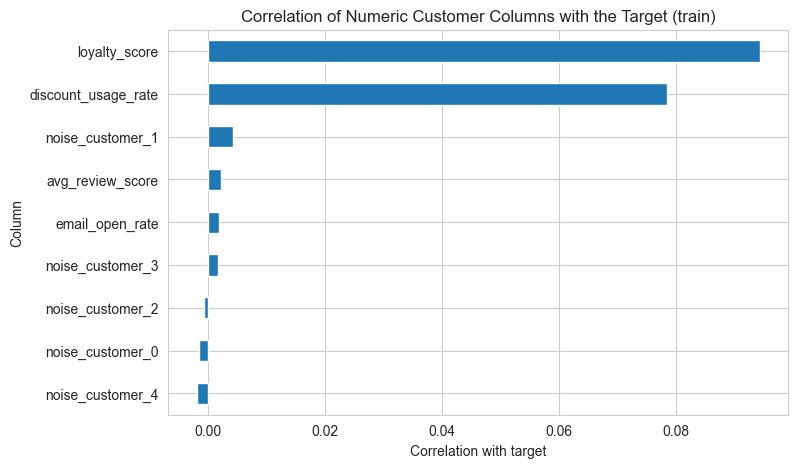

In [106]:
# Correlation of each numeric column with the target
number_cols = ["loyalty_score", "email_open_rate", "discount_usage_rate", "avg_review_score"] + noise_cols
corr_with_target = train_cust[number_cols + ["target"]].corr()["target"].drop("target").sort_values()
print(corr_with_target)

plt.figure(figsize=(8, 5))
corr_with_target.plot(kind="barh")
plt.title("Correlation of Numeric Customer Columns with the Target (train)")
plt.xlabel("Correlation with target")
plt.ylabel("Column")
plt.show()

### Findings – Customers vs target 
- Write which tier or country differs from the overall share.
- If the `noise_customer_*` columns all have correlations near 0 (about -0.02 to 0.02), that supports the name "noise". If one is clearly larger, keep it and tell the team. **Keep all noise columns until the team decides.**

In [107]:
# Do customers with target = 1 have more or fewer transactions/sessions? (train only; counts only)
transactions_per_customer = transactions["customer_id"].value_counts()
sessions_per_customer = sessions["customer_id"].value_counts()

check = train[["customer_id", "target"]].copy()
# map() looks up each customer's count; customers with no rows get NaN, fillna(0) makes it 0
check["n_transactions"] = check["customer_id"].map(transactions_per_customer).fillna(0)
check["n_sessions"] = check["customer_id"].map(sessions_per_customer).fillna(0)

print(check.groupby("target")[["n_transactions", "n_sessions"]].mean())

        n_transactions  n_sessions
target                            
0             2.505999    9.996142
1             2.483439   10.009943


### Findings – Leakage warning 
- If customers with target = 1 have far more or far fewer transactions than target = 0, the target may be **built from the same history**. Using all transactions as features could then leak the answer.
- **Before feature engineering, ask the team:** what is the target definition, and what date is "today" for the prediction? Only data from **before** that date may be used as features.